# 01 · Viabilidad del detector (Detector-0)

**Pregunta:** ¿cuánto rinde un YOLO preentrenado en COCO, *tal cual* (sin entrenar), para **contar botellas y latas**?

- Modelo: `yolo26n.pt` (y `yolo26s.pt` para comparar), Ultralytics, CPU, tamaño 640.
- COCO no tiene la clase *lata*: se prueban dos variantes de filtrado, solo `bottle` (39) y `bottle`+`cup` (39+41).
- Barrido de umbral de confianza: 0.25, 0.4 y 0.5.
- Métricas por imagen: error de conteo (MAE, % exacto, sesgo) y detección (precisión/recall con IoU ≥ 0.5).

La lógica está en `scripts/viabilidad_detector.py`; este notebook la llama y muestra tablas y gráficos.
El resultado es la **línea base** contra la que se compara el detector entrenado (notebook 04).

In [1]:
import sys
from pathlib import Path
print(sys.executable)

# RAIZ = repo del proyecto (datos pesados y modelos). REPO = checkout donde se versionan los resultados.
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
MAIN = Path(r"C:\Users\limber\Documents\Semestres\2-2026\Preparacion Decisiones\IA\control_inventario")
RAIZ = REPO if (REPO / "datos" / "viabilidad" / "salidas" / "raw").exists() else MAIN
SCRIPT = REPO / "scripts" / "viabilidad_detector.py"
RES = REPO / "datos" / "viabilidad" / "resultados"
GRAF = REPO / "datos" / "viabilidad" / "graficos"
GRAF.mkdir(parents=True, exist_ok=True)
print("RAIZ :", RAIZ)
print("REPO :", REPO)

C:\Users\limber\anaconda3\envs\inventariovision\python.exe
RAIZ : C:\Users\limber\Documents\Semestres\2-2026\Preparacion Decisiones\IA\control_inventario
REPO : C:\Users\limber\Documents\Semestres\2-2026\Preparacion Decisiones\IA\control_inventario\.claude\worktrees\agent-a512f118512b29c87


## 1. Datos y ejecución

Las imágenes vienen de datasets públicos de Roboflow (descargados con `scripts/viabilidad_descargar.py` a
`datos/viabilidad/salidas/raw/`, ignorado por git). Se usan los splits *test* y *valid*, fotos con ≥ 3 bebidas
y **una sola copia por foto original** (las `<foto>.rf.<hash>.jpg` son aumentos de la misma toma).

El paso completo tarda varios minutos en CPU; con `RECALCULAR = False` se reutilizan los CSV ya generados.

In [2]:
import subprocess
RECALCULAR = not (RES / "metricas.csv").exists()
MODELOS = ["yolo26n.pt", "yolo26s.pt"]
if RECALCULAR:
    cmd = [sys.executable, str(SCRIPT), "todo", "--raiz", str(RAIZ), "--repo", str(REPO), "--modelos", *MODELOS]
    r = subprocess.run(cmd, capture_output=True, text=True, encoding="utf-8")
    print(r.stdout[-4000:], r.stderr[-2000:])
else:
    print("Usando resultados existentes en", RES)

Usando resultados existentes en C:\Users\limber\Documents\Semestres\2-2026\Preparacion Decisiones\IA\control_inventario\.claude\worktrees\agent-a512f118512b29c87\datos\viabilidad\resultados


In [3]:
import pandas as pd
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
sel = pd.read_csv(RES / "seleccion.csv")
cl = pd.read_csv(RES / "clases_datasets.csv")
print(f"{len(sel)} imágenes · {sel.n_real.sum()} bebidas reales "
      f"({sel.n_botella.sum()} botellas, {sel.n_lata.sum()} latas)")
display(sel.groupby("dataset").agg(imagenes=("imagen", "size"), bebidas=("n_real", "sum"),
                                    botellas=("n_botella", "sum"), latas=("n_lata", "sum"),
                                    media_por_img=("n_real", "mean"), max_por_img=("n_real", "max")).round(1))
display(cl.pivot_table(index="dataset", columns="tipo", values="clase", aggfunc=lambda s: ", ".join(s)))

90 imágenes · 1079 bebidas reales (825 botellas, 254 latas)


,imagenes,bebidas,botellas,latas,media_por_img,max_por_img
dataset,,,,,,
roboflow-100__soda-bottles,45,715,715,0,15.9,32
rosd__final_hr,45,364,110,254,8.1,13


tipo,botella,excluir,lata
dataset,,,
darians-workspace-4fake__bottle-detection-q9eas,"Bonafont_botella, Bottle-Detection, Coca_Origi...",NonBottle,"Cans, Coca_Light_Can, Coca_Original_Can, Fanta..."
roboflow-100__soda-bottles,"coca-cola, fanta, sprite",NaN,NaN
rosd__final_hr,"coke_bottle, fanta_bottle, pepsi_bottle, sprit...",NaN,"7up_can, beer_can, coke_can, juice_can, milk_c..."


## 2. Métricas por modelo, umbral y variante

In [4]:
met = pd.read_csv(RES / "metricas.csv")
cols = ["modelo", "umbral", "variante", "MAE", "MAE_rel_%", "exacto_%", "sesgo", "sub_%", "sobre_%",
        "P", "R", "F1", "R_botellas", "R_latas"]
display(met[cols].round(3))

,modelo,umbral,variante,MAE,MAE_rel_%,exacto_%,sesgo,sub_%,sobre_%,P,R,F1,R_botellas,R_latas
0,yolo26n,0.25,bottle,9.544,68.878,12.222,-9.544,87.778,0.0,0.991,0.202,0.336,0.118,0.476
1,yolo26n,0.25,bottle+cup,9.522,68.560,12.222,-9.522,87.778,0.0,0.986,0.203,0.337,0.118,0.480
2,yolo26n,0.40,bottle,10.033,75.512,6.667,-10.033,93.333,0.0,0.994,0.162,0.279,0.104,0.350
3,yolo26n,0.40,bottle+cup,10.033,75.512,6.667,-10.033,93.333,0.0,0.994,0.162,0.279,0.104,0.350
4,yolo26n,0.50,bottle,10.344,79.579,3.333,-10.344,96.667,0.0,0.993,0.136,0.240,0.101,0.252
5,yolo26n,0.50,bottle+cup,10.344,79.579,3.333,-10.344,96.667,0.0,0.993,0.136,0.240,0.101,0.252
6,yolo26s,0.25,bottle,7.978,58.557,5.556,-7.978,94.444,0.0,0.958,0.321,0.481,0.274,0.472
7,yolo26s,0.25,bottle+cup,7.711,56.596,6.667,-7.711,93.333,0.0,0.943,0.336,0.496,0.293,0.476
8,yolo26s,0.40,bottle,8.856,66.825,3.333,-8.856,96.667,0.0,0.975,0.255,0.404,0.230,0.335
9,yolo26s,0.40,bottle+cup,8.822,66.578,3.333,-8.822,96.667,0.0,0.975,0.258,0.408,0.234,0.335


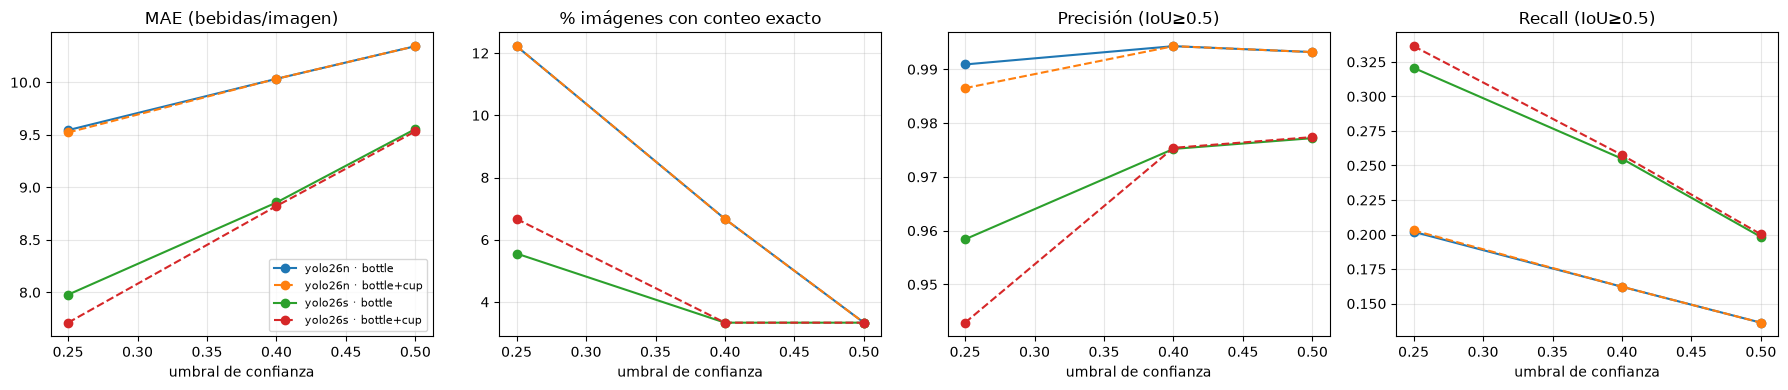

In [5]:
import matplotlib.pyplot as plt
fig, ejes = plt.subplots(1, 4, figsize=(18, 4))
for (mod, var), g in met.groupby(["modelo", "variante"]):
    estilo = "-" if var == "bottle" else "--"
    for ax, col in zip(ejes, ["MAE", "exacto_%", "P", "R"]):
        ax.plot(g.umbral, g[col], estilo, marker="o", label=f"{mod} · {var}")
for ax, t in zip(ejes, ["MAE (bebidas/imagen)", "% imágenes con conteo exacto", "Precisión (IoU≥0.5)", "Recall (IoU≥0.5)"]):
    ax.set_title(t); ax.set_xlabel("umbral de confianza"); ax.grid(alpha=.3)
ejes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(GRAF / "metricas_vs_umbral.png", dpi=110); plt.show()

## 3. Real vs. detectado (mejor configuración de `yolo26n`)

Mejor configuración yolo26n: 0.25 bottle+cup · MAE 9.52


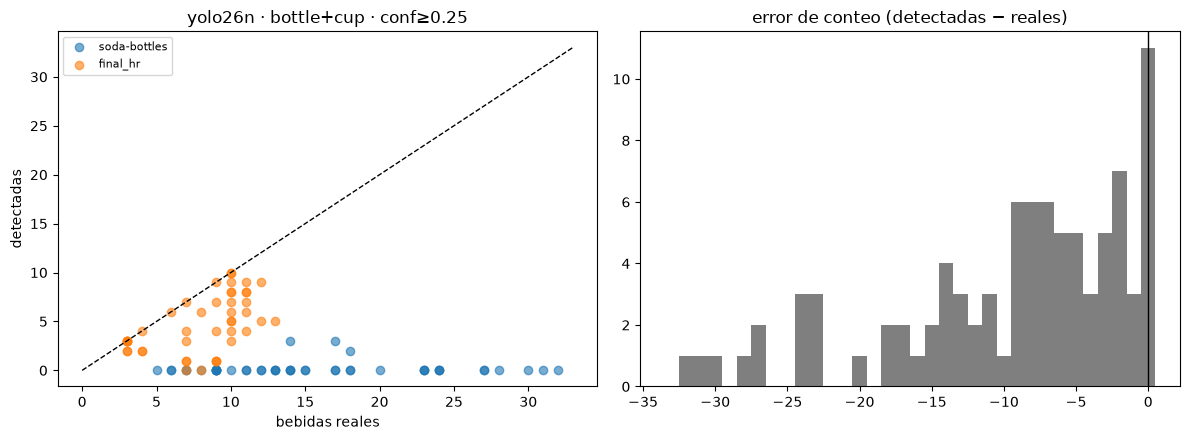

,dataset,variante,imagenes,MAE,exacto_%,sesgo,P,R,R_botellas,R_latas
0,roboflow-100__soda-bottles,bottle,45.0,15.711,0.000,-15.711,1.000,0.011,0.011,0.000
1,rosd__final_hr,bottle,45.0,3.378,24.444,-3.378,0.991,0.577,0.809,0.476
2,roboflow-100__soda-bottles,bottle+cup,45.0,15.711,0.000,-15.711,1.000,0.011,0.011,0.000
3,rosd__final_hr,bottle+cup,45.0,3.333,24.444,-3.333,0.986,0.580,0.809,0.480


In [6]:
pi = pd.read_csv(RES / "por_imagen.csv")
n = met[met.modelo == "yolo26n"].sort_values(["MAE", "exacto_%"], ascending=[True, False]).iloc[0]
print("Mejor configuración yolo26n:", n.umbral, n.variante, "· MAE", round(n.MAE, 2))
q = pi[(pi.modelo == "yolo26n") & (pi.umbral == n.umbral) & (pi.variante == n.variante)]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
lim = max(q.n_real.max(), q.n_det.max()) + 1
for ds, g in q.groupby("dataset"):
    ax[0].scatter(g.n_real, g.n_det, alpha=.6, label=ds.split("__")[-1])
ax[0].plot([0, lim], [0, lim], "k--", lw=1); ax[0].set_xlabel("bebidas reales"); ax[0].set_ylabel("detectadas")
ax[0].set_title(f"yolo26n · {n.variante} · conf≥{n.umbral}"); ax[0].legend(fontsize=8)
ax[1].hist(q.error, bins=range(int(q.error.min()) - 1, int(q.error.max()) + 2), align="left", color="tab:gray")
ax[1].axvline(0, color="k", lw=1); ax[1].set_title("error de conteo (detectadas − reales)")
plt.tight_layout(); plt.savefig(GRAF / "real_vs_detectado.png", dpi=110); plt.show()
display(pd.read_csv(RES / "metricas_por_dataset.csv").query("modelo=='yolo26n' and umbral==@n.umbral")
        [["dataset", "variante", "imagenes", "MAE", "exacto_%", "sesgo", "P", "R", "R_botellas", "R_latas"]].round(3))

## 4. ¿Qué pasa con las latas?

Para cada caja real se busca la detección (cualquiera de las 80 clases COCO, conf ≥ 0.25) con mayor IoU ≥ 0.5
y se anota su clase. `(nada)` = ninguna detección la cubre.

yolo26n


tipo_real,botella,lata
clase_coco,,
(nada),86.3,49.6
bottle,11.8,48.0
cell phone,0.0,2.0
cup,0.0,0.4
fire hydrant,0.2,0.0
orange,1.1,0.0
parking meter,0.1,0.0
person,0.1,0.0


yolo26s


tipo_real,botella,lata
clase_coco,,
(nada),69.1,51.6
bottle,27.0,47.2
cell phone,0.0,0.8
cup,2.2,0.4
snowboard,0.2,0.0
sports ball,1.3,0.0
suitcase,0.1,0.0


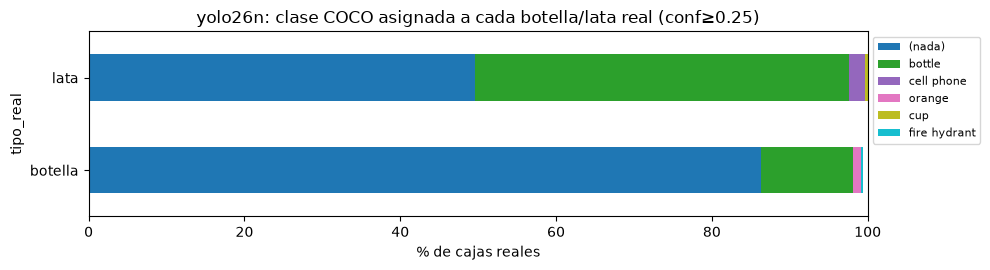

In [7]:
lat = pd.read_csv(RES / "latas_clase_coco.csv")
for mod, g in lat.groupby("modelo"):
    print(mod)
    display(g.pivot_table(index="clase_coco", columns="tipo_real", values="%", fill_value=0).round(1)
             .sort_values("lata", ascending=False).head(8))
g = lat[lat.modelo == "yolo26n"]
piv = g.pivot_table(index="tipo_real", columns="clase_coco", values="%", fill_value=0)
top = piv.max().sort_values(ascending=False).index[:6]
piv[top].plot.barh(stacked=True, figsize=(10, 2.8), colormap="tab10")
plt.xlabel("% de cajas reales"); plt.title("yolo26n: clase COCO asignada a cada botella/lata real (conf≥0.25)")
plt.legend(bbox_to_anchor=(1, 1), fontsize=8); plt.tight_layout()
plt.savefig(GRAF / "latas_clase_coco.png", dpi=110); plt.show()

¿Influye la orientación? Se toma como *de pie* una caja real más alta que ancha y como *acostada* el resto
(en la heladera de `soda-bottles`, vista desde arriba con ojo de pez, esta regla es solo aproximada).

In [8]:
ori = pd.read_csv(RES / "orientacion_clase_coco.csv")
display(ori)

,modelo,dataset,tipo_real,orientacion,n,pct_como_bottle,pct_con_alguna_clase
0,yolo26n,roboflow-100__soda-bottles,botella,acostada,456,0.0,1.3
1,yolo26n,roboflow-100__soda-bottles,botella,de pie,259,3.1,6.9
2,yolo26n,rosd__final_hr,botella,acostada,26,30.8,30.8
3,yolo26n,rosd__final_hr,botella,de pie,84,96.4,96.4
4,yolo26n,rosd__final_hr,lata,acostada,67,3.0,10.4
5,yolo26n,rosd__final_hr,lata,de pie,187,64.2,64.7
6,yolo26s,roboflow-100__soda-bottles,botella,acostada,456,16.0,20.8
7,yolo26s,roboflow-100__soda-bottles,botella,de pie,259,17.4,21.2
8,yolo26s,rosd__final_hr,botella,acostada,26,80.8,80.8
9,yolo26s,rosd__final_hr,botella,de pie,84,100.0,100.0


## 5. Tiempo de inferencia en esta PC (CPU)

{'cpu': 'AMD Ryzen 7 7735HS with Radeon Graphics', 'torch': '2.14.1+cpu', 'cuda': False, 'ultralytics': '8.4.178'}


,modelo,hilos,torch_hilos,imgsz,imagenes,ms_prom,ms_p50,ms_p95,ms_preproceso,ms_inferencia,ms_postproceso,img_por_s
0,yolo26n,1,1,640,60,145.93,133.60,212.32,6.82,137.12,1.35,6.85
1,yolo26n,8,8,640,60,91.71,77.45,148.50,3.62,85.73,1.63,10.90
2,yolo26s,1,1,640,60,398.53,353.92,593.33,7.21,387.93,1.40,2.51
3,yolo26s,8,8,640,60,197.23,172.75,288.78,4.96,186.26,2.10,5.07


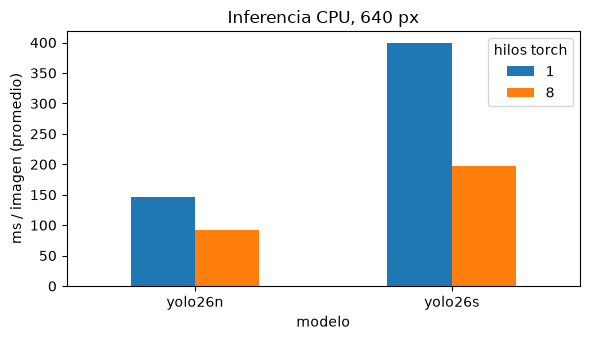

In [9]:
import json
t = pd.read_csv(RES / "tiempos.csv")
print(json.loads((RES / "entorno_tiempos.json").read_text(encoding="utf-8")))
display(t)
ax = t.pivot(index="modelo", columns="hilos", values="ms_prom").plot.bar(figsize=(6, 3.5), rot=0)
ax.set_ylabel("ms / imagen (promedio)"); ax.set_title("Inferencia CPU, 640 px"); ax.legend(title="hilos torch")
plt.tight_layout(); plt.savefig(GRAF / "tiempos.png", dpi=110); plt.show()

## 6. Casos ilustrativos (verde = real, rojo = detectado)

,archivo,imagen,dataset,caso,n_real,n_det,error
0,01_exacto_real10_det10.jpg,rosd__final_hr/test/images/MVIMG_20260416_0004...,rosd__final_hr,exacto,10,10,0
1,02_exacto_real10_det10.jpg,rosd__final_hr/valid/images/MVIMG_20260416_000...,rosd__final_hr,exacto,10,10,0
2,03_exacto_real9_det9.jpg,rosd__final_hr/test/images/MVIMG_20260416_0022...,rosd__final_hr,exacto,9,9,0
3,04_exacto_real7_det7.jpg,rosd__final_hr/valid/images/MVIMG_20260415_235...,rosd__final_hr,exacto,7,7,0
4,05_subconteo_real32_det0.jpg,roboflow-100__soda-bottles/valid/images/01_202...,roboflow-100__soda-bottles,subconteo,32,0,-32
5,06_subconteo_real31_det0.jpg,roboflow-100__soda-bottles/valid/images/01_202...,roboflow-100__soda-bottles,subconteo,31,0,-31
6,07_subconteo_real14_det0.jpg,roboflow-100__soda-bottles/test/images/01_2022...,roboflow-100__soda-bottles,subconteo,14,0,-14
7,08_subconteo_real14_det0.jpg,roboflow-100__soda-bottles/test/images/01_2022...,roboflow-100__soda-bottles,subconteo,14,0,-14
8,09_subconteo_real9_det1.jpg,rosd__final_hr/test/images/MVIMG_20260415_2353...,rosd__final_hr,subconteo,9,1,-8
9,10_subconteo_real8_det0.jpg,rosd__final_hr/test/images/MVIMG_20260415_2353...,rosd__final_hr,subconteo,8,0,-8


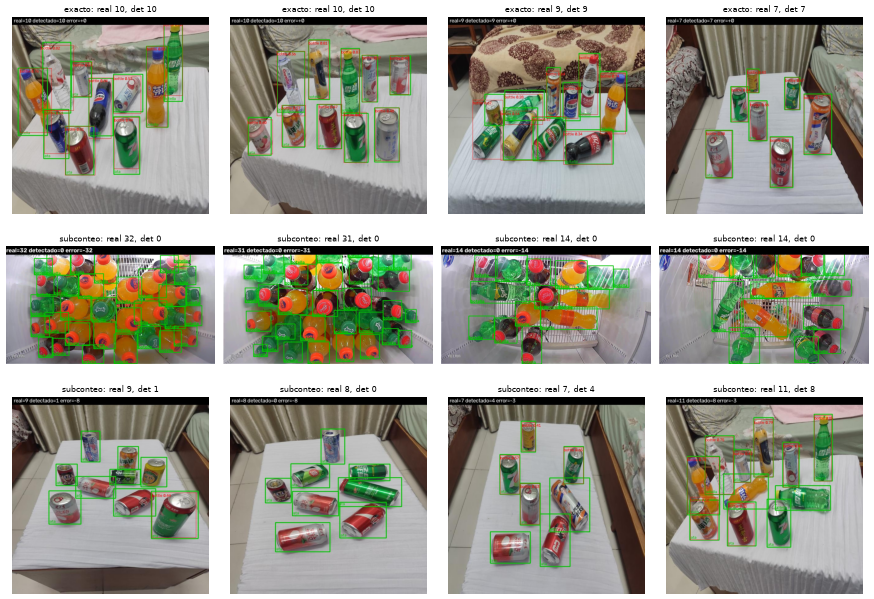

In [10]:
from PIL import Image
casos = pd.read_csv(RES / "casos_anotados.csv")
display(casos)
ANOT = RAIZ / "datos" / "viabilidad" / "salidas" / "anotadas"
fig, ejes = plt.subplots(3, 4, figsize=(16, 11), dpi=55)  # dpi bajo: el .ipynb queda liviano
for ax, c in zip(ejes.ravel(), casos.itertuples()):
    ax.imshow(Image.open(ANOT / c.archivo)); ax.set_title(f"{c.caso}: real {c.n_real}, det {c.n_det}", fontsize=10)
    ax.axis("off")
plt.tight_layout(); plt.show()

## 7. Conclusión

Ver `datos/viabilidad/INFORME.md` (tabla completa, análisis de latas y la línea base numérica).